In [1]:
# Импорты и настройки

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Subset

# torchvision
from torchvision import datasets, transforms, models
from torchvision.utils import make_grid

# scikit-learn (метрики)
from sklearn.metrics import classification_report, confusion_matrix

# ---- Воспроизводимость ----
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

# ---- Устройство ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Используется устройство: cuda
GPU: NVIDIA GeForce RTX 3050
VRAM: 8.6 GB


In [2]:
# Загрузка и предобработка данных (Задание 1)

# ----- Параметры -----
DATA_DIR   = "dataset"   # dataset/birds  и  dataset/drones
IMAGE_SIZE = 128
BATCH_SIZE = 32

# ----- Аугментации для ОБУЧЕНИЯ -----
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3,
                           saturation=0.3, hue=0.05),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ----- Трансформации для ВАЛИДАЦИИ и ТЕСТА (без аугментаций) -----
val_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ----- Загружаем датасет -----
full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transforms)
class_names  = full_dataset.classes
print(f"Классы: {class_names}")
print(f"Всего изображений: {len(full_dataset)}")

# ----- Разбиение 70% train / 15% val / 15% test -----
n_total = len(full_dataset)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

# Зафиксируем split (reproducibility)
generator = torch.Generator().manual_seed(42)
train_idx, val_idx, test_idx = random_split(
    range(n_total), [n_train, n_val, n_test], generator=generator
)

# Создаём отдельные датасеты с нужными трансформациями
train_dataset = Subset(
    datasets.ImageFolder(DATA_DIR, transform=train_transforms),
    list(train_idx)
)
val_dataset = Subset(
    datasets.ImageFolder(DATA_DIR, transform=val_transforms),
    list(val_idx)
)
test_dataset = Subset(
    datasets.ImageFolder(DATA_DIR, transform=val_transforms),
    list(test_idx)
)

print(f"\nРазбиение датасета:")
print(f"  Train : {len(train_dataset)} ({len(train_dataset)/n_total*100:.0f}%)")
print(f"  Val   : {len(val_dataset)}  ({len(val_dataset)/n_total*100:.0f}%)")
print(f"  Test  : {len(test_dataset)}  ({len(test_dataset)/n_total*100:.0f}%)")

# ----- DataLoader'ы -----
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0, pin_memory=True)

print(f"\nBatch size: {BATCH_SIZE}")
print(f"Train batches: {len(train_loader)}")
print(f"Val   batches: {len(val_loader)}")
print(f"Test  batches: {len(test_loader)}")


Классы: ['birds', 'drones']
Всего изображений: 359

Разбиение датасета:
  Train : 251 (70%)
  Val   : 53  (15%)
  Test  : 55  (15%)

Batch size: 32
Train batches: 8
Val   batches: 2
Test  batches: 2


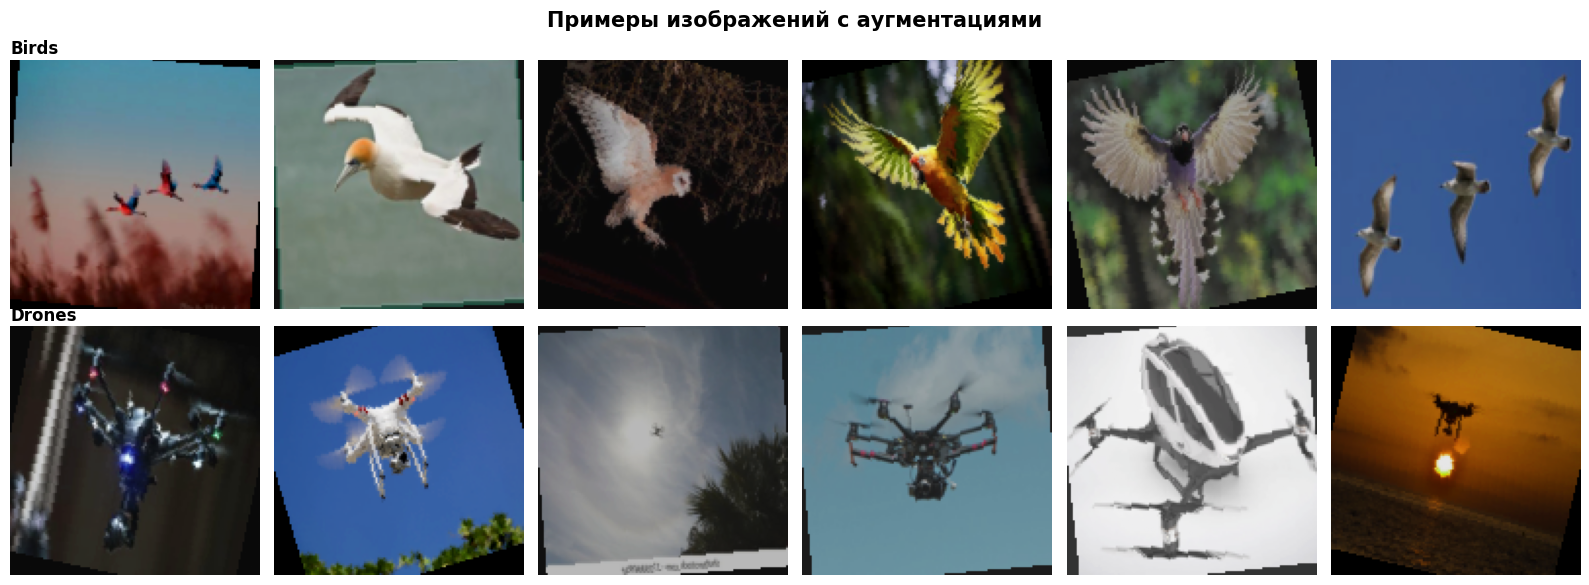

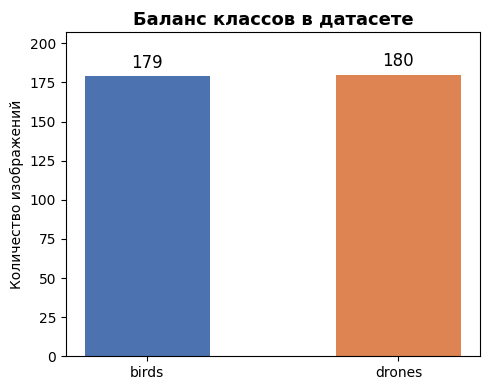

Датасет загружен и готов к обучению!


In [3]:
# Визуализация датасета (примеры изображений)

def denormalize(tensor):
    """Обратная нормализация для отображения."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return torch.clamp(tensor * std + mean, 0, 1)

# --- Примеры из каждого класса ---
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle("Примеры изображений с аугментациями", fontsize=15, fontweight="bold")

for class_idx, class_name in enumerate(class_names):
    # Выбираем 6 случайных изображений класса из train
    class_indices = [i for i in train_idx
                     if full_dataset.targets[i] == class_idx]
    sample_idx = random.sample(class_indices, 6)

    for col, idx in enumerate(sample_idx):
        img_tensor, label = full_dataset[idx]
        img = denormalize(img_tensor).permute(1, 2, 0).numpy()
        ax = axes[class_idx][col]
        ax.imshow(img)
        ax.axis("off")
        if col == 0:
            ax.set_title(class_name.capitalize(), fontsize=12,
                         fontweight="bold", loc="left", pad=4)

plt.tight_layout()
plt.savefig("dataset_samples.png", dpi=120, bbox_inches="tight")
plt.show()

# --- Баланс классов ---
labels = full_dataset.targets
fig, ax = plt.subplots(figsize=(5, 4))
counts = [labels.count(i) for i in range(len(class_names))]
bars = ax.bar(class_names, counts, color=["#4C72B0", "#DD8452"], width=0.5)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=12)
ax.set_title("Баланс классов в датасете", fontsize=13, fontweight="bold")
ax.set_ylabel("Количество изображений")
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

print("Датасет загружен и готов к обучению!")


In [4]:
# ──────────────────────────────────────────
# Архитектура 1: SimpleCNN (базовая)
# ──────────────────────────────────────────
class SimpleCNN(nn.Module):
    """
    Классическая CNN без регуляризации.
    3 сверточных блока: Conv → ReLU → MaxPool
    Полносвязные слои: FC(1024→256→2)
    Нет BatchNorm, есть только один Dropout.
    """
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            # Блок 1: 3 → 32 каналов
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # 128×128
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),                            # 64×64
            # Блок 2: 32 → 64 каналов
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 64×64
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),                            # 32×32
            # Блок 3: 64 → 128 каналов
            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 32×32
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),                            # 16×16
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


In [5]:
class BN_DeepCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            # Блок 1: 3 -> 32
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.MaxPool2d(2), nn.Dropout2d(0.1),
            # Блок 2: 32 -> 64
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.MaxPool2d(2), nn.Dropout2d(0.1),
            # Блок 3: 64 -> 128
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.MaxPool2d(2),
            # Блок 4: 128 -> 256
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.AdaptiveAvgPool2d(4) # Увеличено разрешение для сохранения деталей
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1024), nn.BatchNorm1d(1024), nn.ReLU(True), nn.Dropout(0.4),
            nn.Linear(1024, 256), nn.BatchNorm1d(256), nn.ReLU(True), nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    def forward(self, x): return self.classifier(self.features(x))


In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        # Shortcut: если каналы или размер отличаются — проекция
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(self.conv_block(x) + self.shortcut(x))
class ResidualCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        # Stem: начальная свёртка для извлечения базовых признаков
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),  # 64×64
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),                   # 32×32
        )
        # Residual блоки
        self.layer1 = ResidualBlock(64, 64)           # 32×32
        self.layer2 = ResidualBlock(64, 128, stride=2)  # 16×16
        self.layer3 = ResidualBlock(128, 256, stride=2) # 8×8
        # Global Average Pooling: убираем зависимость от размера входа
        self.pool = nn.AdaptiveAvgPool2d(1)           # 256×1×1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        return self.classifier(x)

In [7]:
# Проверка архитектур (подсчёт параметров)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def model_summary(name, model):
    dummy = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        out = model(dummy)
    n = count_params(model)
    print(f"{'─'*50}")
    print(f"  {name}")
    print(f"  Параметры: {n:,}")
    print(f"  Output shape: {out.shape}")

model_summary("SimpleCNN",     SimpleCNN())
model_summary("BN_DeepCNN",    BN_DeepCNN())
model_summary("ResidualCNN",   ResidualCNN())
print(f"{'─'*50}")


──────────────────────────────────────────────────
  SimpleCNN
  Параметры: 8,482,626
  Output shape: torch.Size([1, 2])
──────────────────────────────────────────────────
  BN_DeepCNN
  Параметры: 5,634,978
  Output shape: torch.Size([1, 2])
──────────────────────────────────────────────────
  ResidualCNN
  Параметры: 1,233,218
  Output shape: torch.Size([1, 2])
──────────────────────────────────────────────────


In [8]:
# Обновленный цикл обучения (вывод всех эпох)

import time
import copy

def train_model(model, train_loader, val_loader,
                num_epochs=30, lr=1e-3, weight_decay=1e-4,
                patience=7, model_name="model"):
    model = model.to(device)

    criterion  = nn.CrossEntropyLoss()
    optimizer  = optim.Adam(model.parameters(), lr=lr,
                            weight_decay=weight_decay)
    scheduler  = optim.lr_scheduler.StepLR(optimizer,
                                           step_size=10, gamma=0.5)

    history = {"train_loss": [], "val_loss": [],
                "train_acc":  [], "val_acc":  []}

    best_val_acc  = 0.0
    best_weights  = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, num_epochs + 1):
        # ── TRAIN ──────────────────────────────────────────
        model.train()
        train_loss, train_correct = 0.0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss    += loss.item() * imgs.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()

        # ── VALIDATION ─────────────────────────────────────
        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs  = model(imgs)
                loss     = criterion(outputs, labels)
                val_loss    += loss.item() * imgs.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        scheduler.step()

        # ── Метрики ────────────────────────────────────────
        n_train, n_val = len(train_loader.dataset), len(val_loader.dataset)
        t_loss, t_acc = train_loss / n_train, train_correct / n_train
        v_loss, v_acc = val_loss / n_val, val_correct / n_val

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["train_acc"].append(t_acc)
        history["val_acc"].append(v_acc)

        # ── ВЫВОД ────────────────────────────────────────────
        elapsed = time.time() - start
        print(f"Epoch [{epoch:>2}/{num_epochs}]  "
              f"Train loss: {t_loss:.4f}  acc: {t_acc:.4f}  │  "
              f"Val loss: {v_loss:.4f}  acc: {v_acc:.4f}  │  "
              f"LR: {scheduler.get_last_lr()[0]:.5f}  "
              f"({elapsed:.0f}s)")

        # ── Early Stopping ─────────────────────────────────
        if v_acc > best_val_acc:
            best_val_acc = v_acc
            best_weights = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if epochs_no_improve >= patience:
            print(f"\n⏹ Early stopping на эпохе {epoch} (лучший val_acc={best_val_acc:.4f})")
            break

    model.load_state_dict(best_weights)
    print(f"\n✓ {model_name} обучена. Лучший val_acc={best_val_acc:.4f}")
    return model, history


In [9]:
# Функция построения графиков


def plot_history(history, model_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    epochs = range(1, len(history["train_loss"]) + 1)

    # Loss
    ax1.plot(epochs, history["train_loss"], label="Train",  marker="o", ms=3)
    ax1.plot(epochs, history["val_loss"],   label="Val",    marker="o", ms=3)
    ax1.set_title(f"{model_name} — Loss")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)

    # Accuracy
    ax2.plot(epochs, history["train_acc"], label="Train", marker="o", ms=3)
    ax2.plot(epochs, history["val_acc"],   label="Val",   marker="o", ms=3)
    ax2.set_title(f"{model_name} — Accuracy")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
    ax2.set_ylim(0, 1); ax2.legend(); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"history_{model_name}.png", dpi=120, bbox_inches="tight")
    plt.show()


  Обучение SimpleCNN


Epoch [ 1/30]  Train loss: 0.9416  acc: 0.5020  │  Val loss: 0.6869  acc: 0.5472  │  LR: 0.00100  (8s)
Epoch [ 2/30]  Train loss: 0.6991  acc: 0.4980  │  Val loss: 0.6890  acc: 0.5472  │  LR: 0.00100  (17s)
Epoch [ 3/30]  Train loss: 0.6949  acc: 0.4980  │  Val loss: 0.6909  acc: 0.5472  │  LR: 0.00100  (26s)
Epoch [ 4/30]  Train loss: 0.6942  acc: 0.4980  │  Val loss: 0.6859  acc: 0.5472  │  LR: 0.00100  (35s)
Epoch [ 5/30]  Train loss: 0.6908  acc: 0.5339  │  Val loss: 0.6755  acc: 0.6038  │  LR: 0.00100  (43s)
Epoch [ 6/30]  Train loss: 0.6931  acc: 0.5060  │  Val loss: 0.6750  acc: 0.5660  │  LR: 0.00100  (52s)
Epoch [ 7/30]  Train loss: 0.6663  acc: 0.5857  │  Val loss: 0.6688  acc: 0.6415  │  LR: 0.00100  (60s)
Epoch [ 8/30]  Train loss: 0.6625  acc: 0.5976  │  Val loss: 0.6157  acc: 0.6604  │  LR: 0.00100  (69s)
Epoch [ 9/30]  Train loss: 0.6309  acc: 0.6295  │  Val loss: 0.6848  acc: 0.5849  │  LR: 0.00100  (77s)
Epoch [10/30]  Train loss: 0.6493  acc: 0.6534  │  Val loss: 0.60

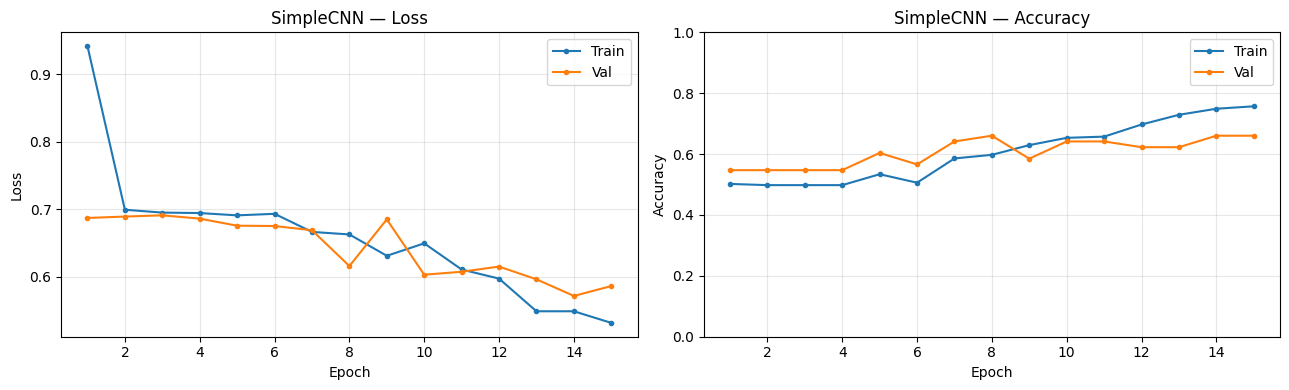


  Обучение BN_DeepCNN
Epoch [ 1/30]  Train loss: 0.7505  acc: 0.5418  │  Val loss: 0.7023  acc: 0.4528  │  LR: 0.00100  (9s)
Epoch [ 2/30]  Train loss: 0.6948  acc: 0.5857  │  Val loss: 0.8065  acc: 0.5472  │  LR: 0.00100  (18s)
Epoch [ 3/30]  Train loss: 0.6248  acc: 0.6574  │  Val loss: 0.8807  acc: 0.4717  │  LR: 0.00100  (27s)
Epoch [ 4/30]  Train loss: 0.6037  acc: 0.6773  │  Val loss: 2.5806  acc: 0.5849  │  LR: 0.00100  (36s)
Epoch [ 5/30]  Train loss: 0.6171  acc: 0.6773  │  Val loss: 0.6035  acc: 0.5849  │  LR: 0.00100  (44s)
Epoch [ 6/30]  Train loss: 0.5591  acc: 0.7171  │  Val loss: 0.6085  acc: 0.6604  │  LR: 0.00100  (54s)
Epoch [ 7/30]  Train loss: 0.5277  acc: 0.7450  │  Val loss: 0.5167  acc: 0.7170  │  LR: 0.00100  (62s)
Epoch [ 8/30]  Train loss: 0.6125  acc: 0.6693  │  Val loss: 0.6670  acc: 0.6415  │  LR: 0.00100  (71s)
Epoch [ 9/30]  Train loss: 0.5621  acc: 0.6733  │  Val loss: 0.5672  acc: 0.6415  │  LR: 0.00100  (80s)
Epoch [10/30]  Train loss: 0.5311  acc: 0.

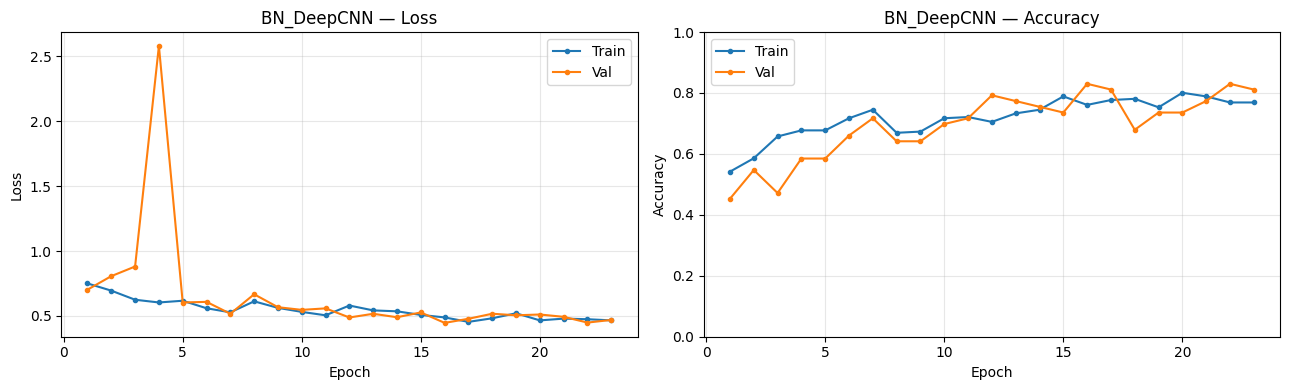


  Обучение ResidualCNN
Epoch [ 1/30]  Train loss: 0.9235  acc: 0.5259  │  Val loss: 0.6646  acc: 0.5472  │  LR: 0.00100  (8s)
Epoch [ 2/30]  Train loss: 0.7702  acc: 0.5179  │  Val loss: 1.0357  acc: 0.5472  │  LR: 0.00100  (16s)
Epoch [ 3/30]  Train loss: 0.7032  acc: 0.5896  │  Val loss: 0.6797  acc: 0.5283  │  LR: 0.00100  (25s)
Epoch [ 4/30]  Train loss: 0.6881  acc: 0.6096  │  Val loss: 0.6237  acc: 0.6226  │  LR: 0.00100  (33s)
Epoch [ 5/30]  Train loss: 0.6745  acc: 0.6016  │  Val loss: 0.6430  acc: 0.5849  │  LR: 0.00100  (41s)
Epoch [ 6/30]  Train loss: 0.6282  acc: 0.6454  │  Val loss: 0.6491  acc: 0.5849  │  LR: 0.00100  (50s)
Epoch [ 7/30]  Train loss: 0.6227  acc: 0.6574  │  Val loss: 0.6405  acc: 0.6415  │  LR: 0.00100  (58s)
Epoch [ 8/30]  Train loss: 0.6568  acc: 0.6056  │  Val loss: 0.6139  acc: 0.5660  │  LR: 0.00100  (67s)
Epoch [ 9/30]  Train loss: 0.6052  acc: 0.6614  │  Val loss: 0.5589  acc: 0.6604  │  LR: 0.00100  (75s)
Epoch [10/30]  Train loss: 0.5992  acc: 0

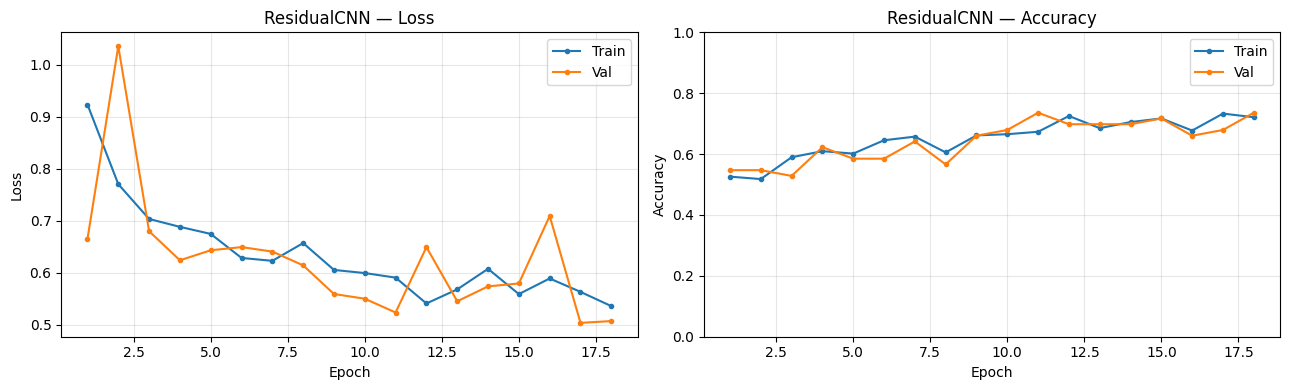


💾 Все модели сохранены.


In [10]:
# ЗАПУСК ОБУЧЕНИЯ всех трёх моделей


results = {}   # сюда сохраним историю для сравнения

# --- SimpleCNN ---
print("=" * 60)
print("  Обучение SimpleCNN")
print("=" * 60)
model_simple, hist_simple = train_model(
    SimpleCNN(), train_loader, val_loader,
    num_epochs=30, lr=1e-3, patience=7,
    model_name="SimpleCNN"
)
plot_history(hist_simple, "SimpleCNN")
results["SimpleCNN"] = hist_simple

# --- BN_DeepCNN ---
print("\n" + "=" * 60)
print("  Обучение BN_DeepCNN")
print("=" * 60)
model_bn, hist_bn = train_model(
    BN_DeepCNN(), train_loader, val_loader,
    num_epochs=30, lr=1e-3, patience=7,
    model_name="BN_DeepCNN"
)
plot_history(hist_bn, "BN_DeepCNN")
results["BN_DeepCNN"] = hist_bn

# --- ResidualCNN ---
print("\n" + "=" * 60)
print("  Обучение ResidualCNN")
print("=" * 60)
model_res, hist_res = train_model(
    ResidualCNN(), train_loader, val_loader,
    num_epochs=30, lr=1e-3, patience=7,
    model_name="ResidualCNN"
)
plot_history(hist_res, "ResidualCNN")
results["ResidualCNN"] = hist_res

torch.save(model_simple.state_dict(), "simple_cnn.pth")
torch.save(model_bn.state_dict(),     "batchnorm_cnn.pth")
torch.save(model_res.state_dict(),    "residual_cnn.pth")
print("\n💾 Все модели сохранены.")


In [11]:
# Transfer Learning — ResNet-18

# ── Загружаем предобученный ResNet-18 (ImageNet) ──────────
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in resnet18.parameters():
    param.requires_grad = False

in_features = resnet18.fc.in_features   # = 512
resnet18.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(in_features, 2)
)

resnet18 = resnet18.to(device)

# Считаем параметры: сколько обучаемых vs замороженных
total_params    = sum(p.numel() for p in resnet18.parameters())
trainable_params = sum(p.numel() for p in resnet18.parameters()
                       if p.requires_grad)
print(f"Всего параметров:      {total_params:,}")
print(f"Обучаемых параметров:  {trainable_params:,}")
print(f"Заморожено:            {total_params - trainable_params:,}")


Всего параметров:      11,177,538
Обучаемых параметров:  1,026
Заморожено:            11,176,512


ЭТАП 1: Feature Extraction (обучаем только FC-слой)
───────────────────────────────────────────────────────
Epoch [ 1/10]  Train loss: 0.9459  acc: 0.4542  │  Val loss: 0.5744  acc: 0.6604  │  LR: 0.00100  (9s)
Epoch [ 2/10]  Train loss: 0.7742  acc: 0.5139  │  Val loss: 0.4810  acc: 0.7925  │  LR: 0.00100  (17s)
Epoch [ 3/10]  Train loss: 0.6950  acc: 0.6534  │  Val loss: 0.5254  acc: 0.6415  │  LR: 0.00100  (25s)
Epoch [ 4/10]  Train loss: 0.5790  acc: 0.7012  │  Val loss: 0.3975  acc: 0.9057  │  LR: 0.00100  (34s)
Epoch [ 5/10]  Train loss: 0.5306  acc: 0.7171  │  Val loss: 0.4266  acc: 0.8302  │  LR: 0.00100  (43s)
Epoch [ 6/10]  Train loss: 0.5307  acc: 0.7211  │  Val loss: 0.3887  acc: 0.8491  │  LR: 0.00100  (51s)
Epoch [ 7/10]  Train loss: 0.5426  acc: 0.7410  │  Val loss: 0.3698  acc: 0.8679  │  LR: 0.00100  (60s)
Epoch [ 8/10]  Train loss: 0.4633  acc: 0.7968  │  Val loss: 0.4067  acc: 0.7547  │  LR: 0.00100  (68s)
Epoch [ 9/10]  Train loss: 0.4236  acc: 0.7888  │  Val loss: 

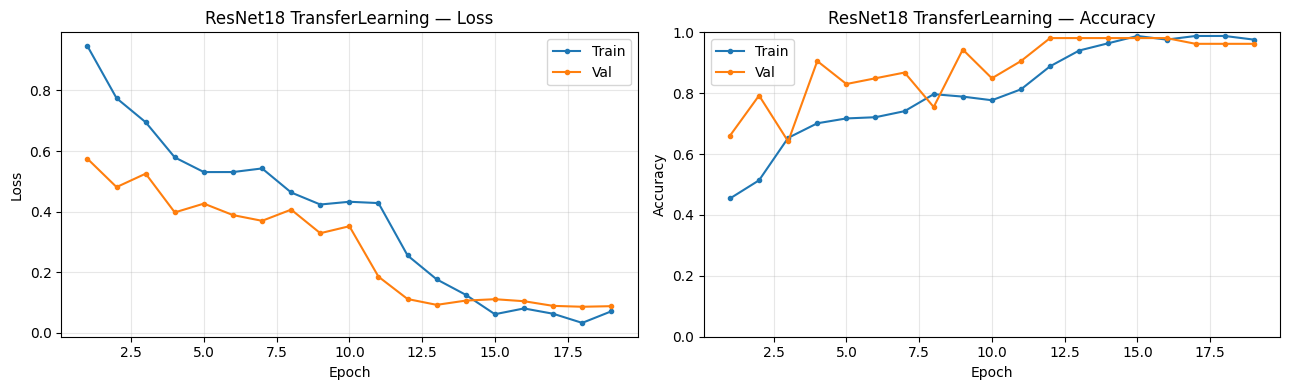


💾 ResNet-18 (Fine-Tuning) завершен и сохранен.


In [12]:
# Обучение ResNet-18 (два этапа)

# ЭТАП 1: Feature Extraction

print("ЭТАП 1: Feature Extraction (обучаем только FC-слой)")
print("─" * 55)

criterion = nn.CrossEntropyLoss()
optimizer_stage1 = optim.Adam(
    filter(lambda p: p.requires_grad, resnet18.parameters()),
    lr=1e-3
)

resnet18, hist_stage1 = train_model(
    resnet18, train_loader, val_loader,
    num_epochs=10,
    lr=1e-3,
    patience=5,
    model_name="ResNet18 (Stage1)",
)


# ЭТАП 2: Fine-Tuning
print("\nЭТАП 2: Fine-Tuning (размораживаем всю сеть)")
print("─" * 55)

for param in resnet18.parameters():
    param.requires_grad = True   # размораживаем все слои

# Диагностика: сколько параметров теперь обучается?
trainable = sum(p.numel() for p in resnet18.parameters() if p.requires_grad)
print(f"Обучаемых параметров в Stage 2: {trainable:,}")

resnet18, hist_stage2 = train_model(
    resnet18, train_loader, val_loader,
    num_epochs=20,
    lr=1e-4,          # Низкий lr, чтобы не испортить предобученные веса
    weight_decay=1e-4,
    patience=7,
    model_name="ResNet18 (Stage2 FineTune)",
)

# Собираем историю для графиков
hist_resnet = {
    "train_loss": hist_stage1["train_loss"] + hist_stage2["train_loss"],
    "val_loss":   hist_stage1["val_loss"]   + hist_stage2["val_loss"],
    "train_acc":  hist_stage1["train_acc"]  + hist_stage2["train_acc"],
    "val_acc":    hist_stage1["val_acc"]    + hist_stage2["val_acc"],
}
results["ResNet18_TL"] = hist_resnet
plot_history(hist_resnet, "ResNet18 TransferLearning")

torch.save(resnet18.state_dict(), "resnet18_tl.pth")
print("\n💾 ResNet-18 (Fine-Tuning) завершен и сохранен.")



Финальные результаты на Тестовой выборке (55 фото):
---------------------------------------------
SimpleCNN       | Test Accuracy: 0.5818
BN_DeepCNN      | Test Accuracy: 0.7818
ResidualCNN     | Test Accuracy: 0.7091
ResNet18_TL     | Test Accuracy: 0.9091


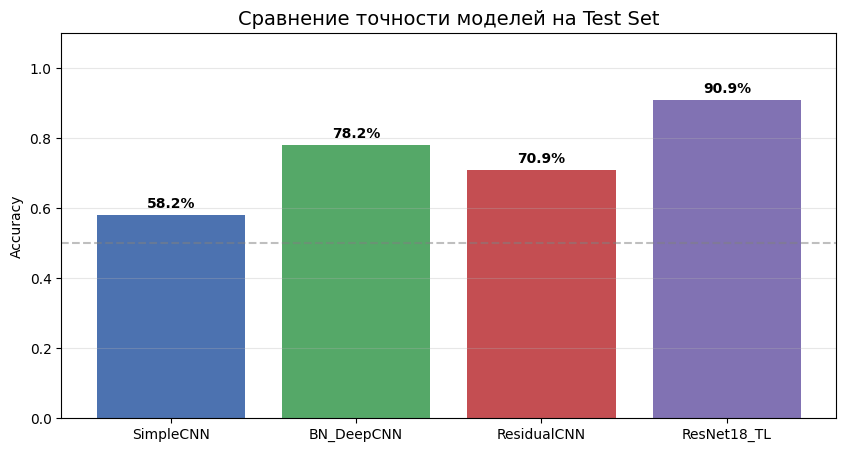


Сводная таблица:
      Model  Test Acc   Params
  SimpleCNN  0.581818  8482626
 BN_DeepCNN  0.781818  5634978
ResidualCNN  0.709091  1233218
ResNet18_TL  0.909091 11177538


In [17]:
# Финальная оценка на TEST SET и Сравнение

def evaluate_model(model, loader, name):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    print(f"{name:15} | Test Accuracy: {acc:.4f}")
    return acc, all_labels, all_preds

print("Финальные результаты на Тестовой выборке (55 фото):")
print("-" * 45)

# Словарь для хранения финальных метрик
final_stats = []

# Оцениваем каждую модель
for name, model in [
    ("SimpleCNN",     model_simple),
    ("BN_DeepCNN",  model_bn),
    ("ResidualCNN",   model_res),
    ("ResNet18_TL",   resnet18)
]:
    acc, labels, preds = evaluate_model(model, test_loader, name)
    final_stats.append({
        "Model": name,
        "Test Acc": acc,
        "Params": count_params(model)
    })

# --- Визуализация сравнения ---
import pandas as pd
df = pd.DataFrame(final_stats)

plt.figure(figsize=(10, 5))
bars = plt.bar(df["Model"], df["Test Acc"], color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='Random chance')
plt.title("Сравнение точности моделей на Test Set", fontsize=14)
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f"{yval:.1%}", ha='center', fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.savefig("models_comparison.png", dpi=120)
plt.show()

# Вывод таблицы параметров
print("\nСводная таблица:")
print(df.to_string(index=False))


Best Model (ResNet18) | Test Accuracy: 0.9091


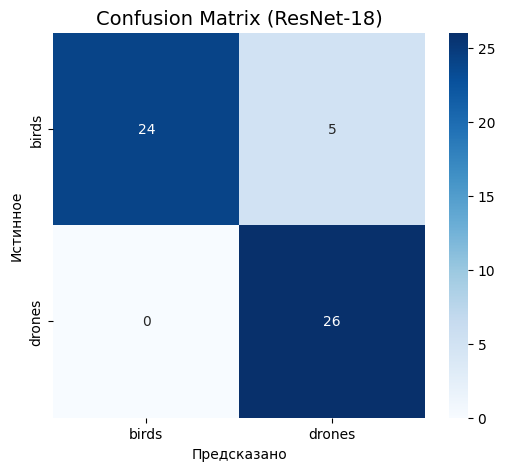


Detailed Report:
              precision    recall  f1-score   support

       birds       1.00      0.83      0.91        29
      drones       0.84      1.00      0.91        26

    accuracy                           0.91        55
   macro avg       0.92      0.91      0.91        55
weighted avg       0.92      0.91      0.91        55

Найдено ошибок на тесте: 5 из 55


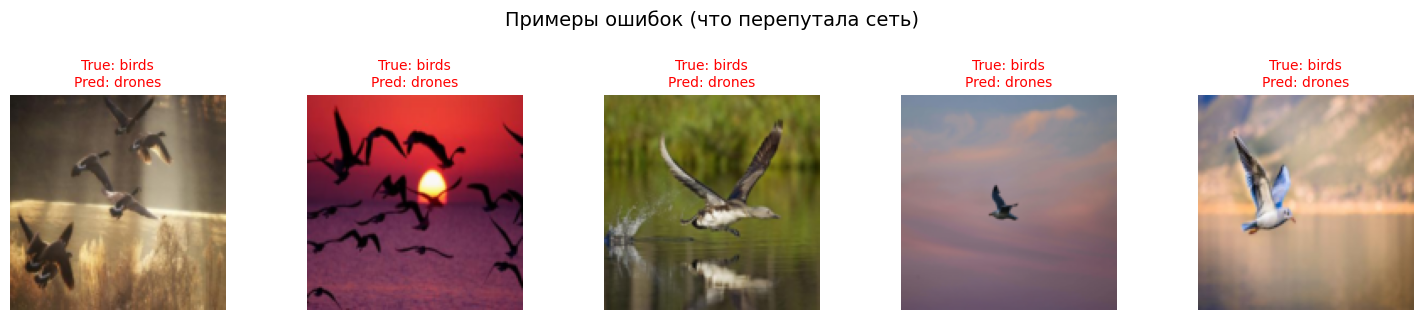

In [ ]:
# Анализ ошибок (Confusion Matrix и визуализация)

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# 1. Считаем предсказания для лучшей модели
acc, y_true, y_pred = evaluate_model(resnet18, test_loader, "Best Model (ResNet18)")

# 2. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Предсказано')
plt.ylabel('Истинное')
plt.title('Confusion Matrix (ResNet-18)', fontsize=14)
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

print("\nDetailed Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 3. Находим индексы ошибок
errors = [i for i, (a, b) in enumerate(zip(y_true, y_pred)) if a != b]
print(f"Найдено ошибок на тесте: {len(errors)} из {len(y_true)}")

if len(errors) > 0:
    # Визуализируем ошибки (до 6 штук)
    n_show = min(len(errors), 6)
    plt.figure(figsize=(15, 3))
    plt.suptitle("Примеры ошибок (что перепутала сеть)", fontsize=14, y=1.05)
    
    for i, err_idx in enumerate(errors[:n_show]):
        # Достаем саму картинку из test_dataset
        img_tensor, label = test_dataset[err_idx]
        img = denormalize(img_tensor).permute(1, 2, 0).numpy()
        
        plt.subplot(1, n_show, i+1)
        plt.imshow(img)
        plt.title(f"True: {class_names[label]}\nPred: {class_names[y_pred[err_idx]]}", 
                  color='red', fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Ошибок не найдено!")
